In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Paràmetres del dataset
n_mostres = 1000
n_variables = 6
np.random.seed(42)

X_base = np.random.normal(loc=0.0, scale=1.0, size=(n_mostres, n_variables))

matriu_mescla = np.maximum(
    np.random.uniform(0.75, 1.25, size=(n_variables,n_variables)),
    2*np.eye(n_variables)) -1 

# 3. Aplicar la mescla per introduir petites correlacions creuades
X_sintetic = np.dot(X_base, matriu_mescla)

# Convertir a DataFrame de Pandas
noms_columnes = [f"Var_{i+1}" for i in range(n_variables)]
df = pd.DataFrame(X_sintetic, columns=noms_columnes)

# 4. Comprovació: Mostrar la matriu de correlació
print("Matriu de Correlació:")
print(df.corr().round(2))

Matriu de Correlació:
       Var_1  Var_2  Var_3  Var_4  Var_5  Var_6
Var_1   1.00  -0.19   0.10   0.10   0.07  -0.24
Var_2  -0.19   1.00  -0.03   0.05   0.43  -0.28
Var_3   0.10  -0.03   1.00   0.25   0.04   0.07
Var_4   0.10   0.05   0.25   1.00  -0.29  -0.05
Var_5   0.07   0.43   0.04  -0.29   1.00   0.01
Var_6  -0.24  -0.28   0.07  -0.05   0.01   1.00


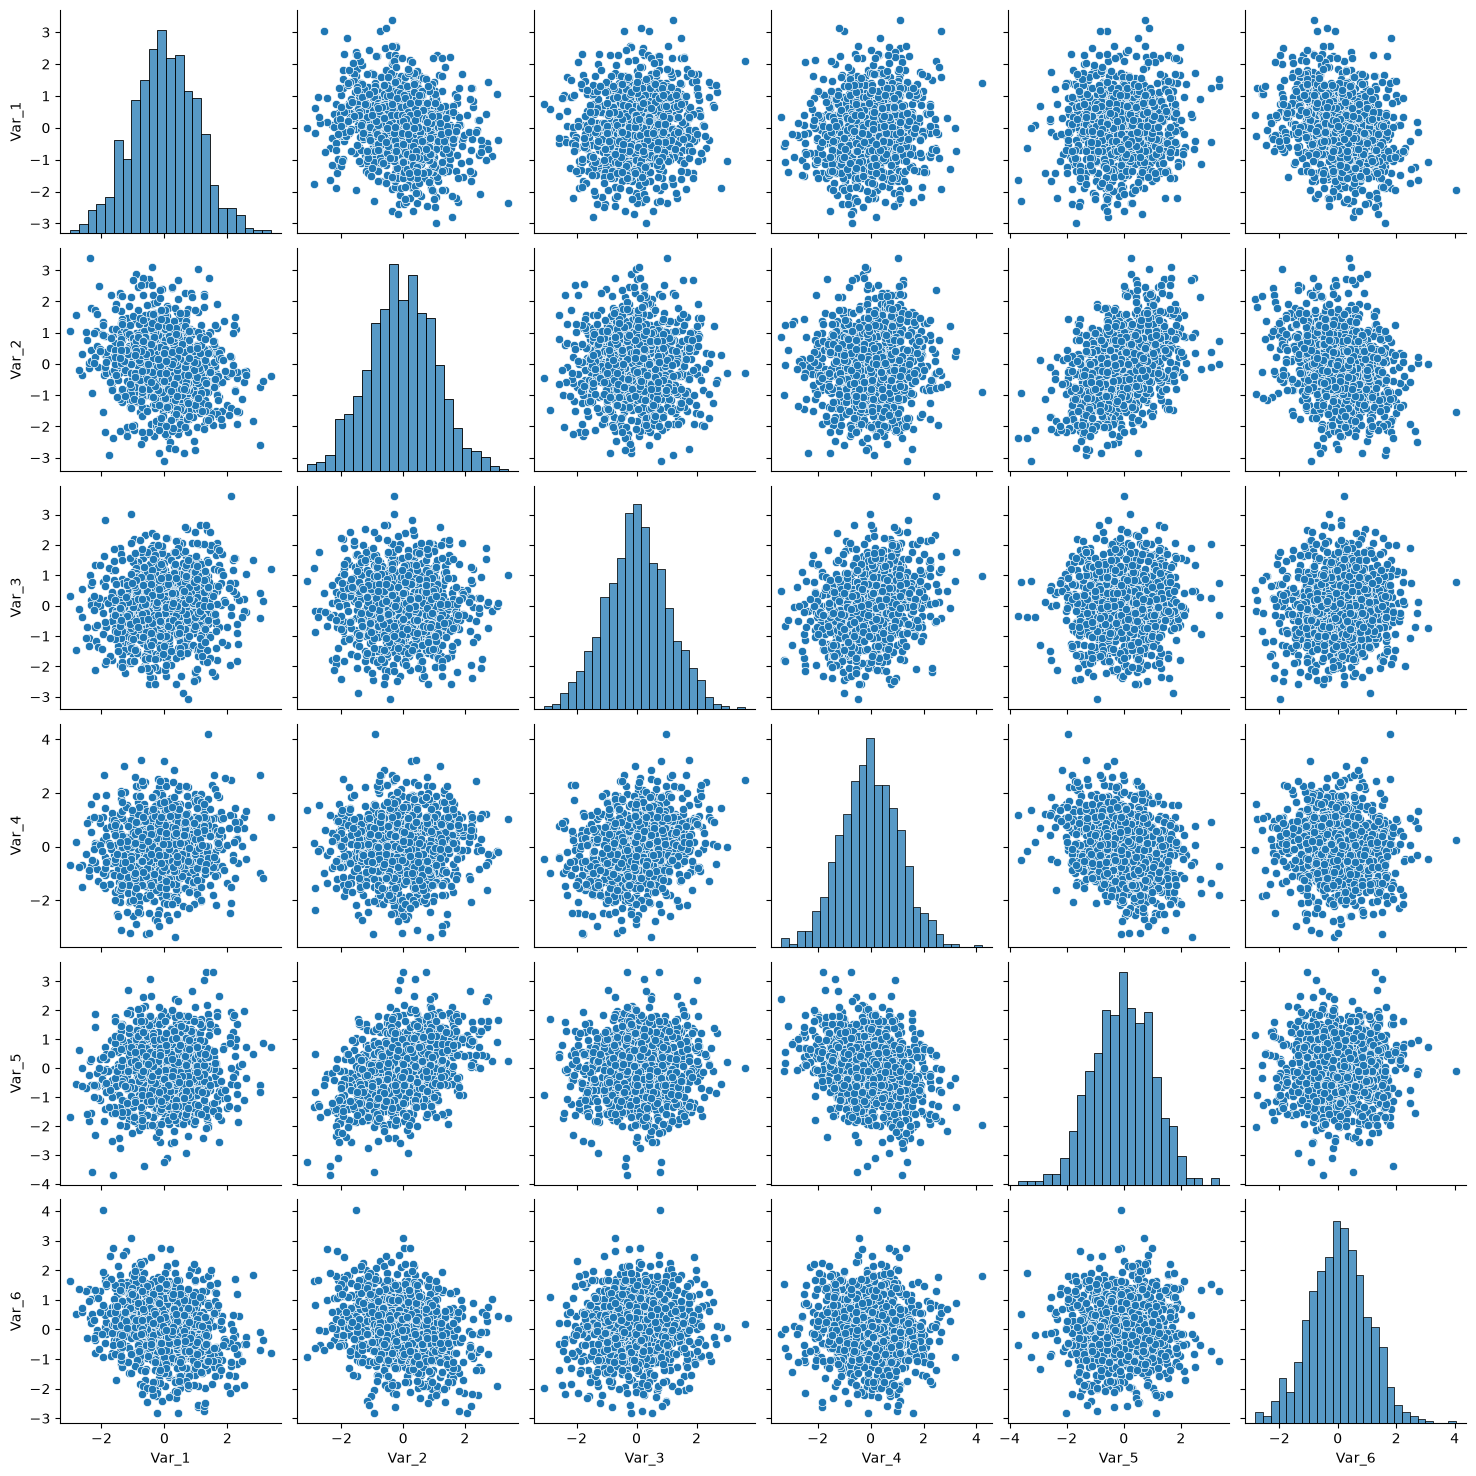

In [4]:
sns.pairplot(data=df)

$$y = 2\text{Var}_1 + \text{Var}_2^2 + (\text{Var}_3 - 1)^2 + 3\sin(5\text{Var}_4) + \text{Var}_5\text{Var}_6$$
```
y =  2 * df["Var_1"] +  df["Var_2"]**2 + (df["Var_3"] - 1)**2 + 3 * np.sin(5*df["Var_4"]) + df["Var_5"] * df["Var_6"]                  
```

In [5]:
y =  2 * df["Var_1"] +  df["Var_2"]**2 + (df["Var_3"] - 1)**2 + 3 * np.sin(5*df["Var_4"]) + df["Var_5"] * df["Var_6"]                  


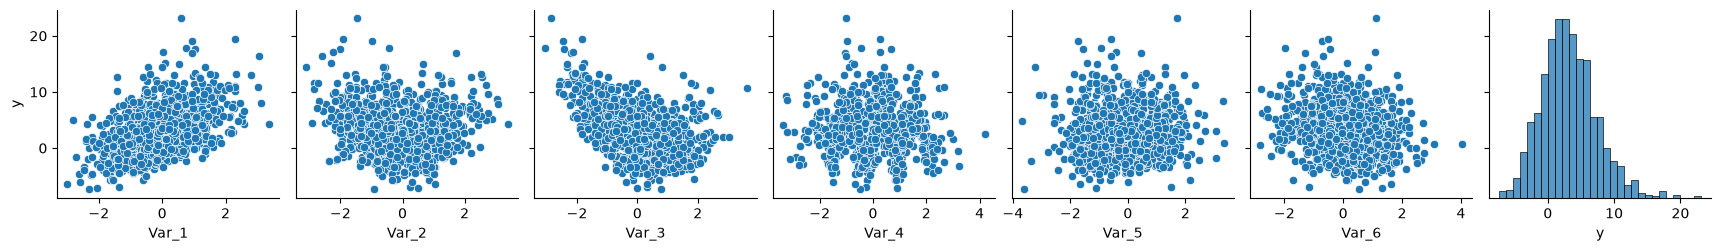

In [6]:
df_final = df.copy()
df_final["y"] = y
sns.pairplot(data=df_final, y_vars="y" )

In [7]:
corr = df_final.corr()
corr.loc["y"]

Var_1    0.468095
Var_2   -0.094197
Var_3   -0.450785
Var_4   -0.058795
Var_5    0.005779
Var_6   -0.165262
y        1.000000
Name: y, dtype: float64

<Axes: >

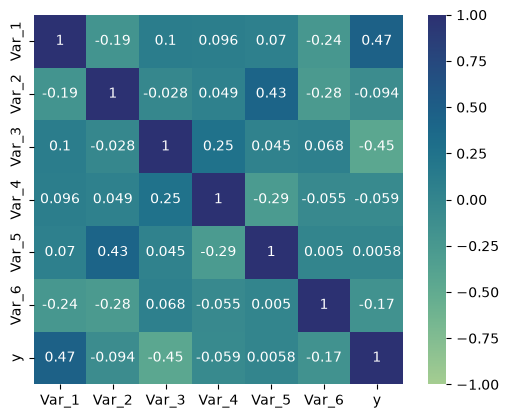

In [8]:
sns.heatmap(corr, square=True, annot=True, vmin=-1, vmax=1, cmap="crest")

In [9]:
corr = df_final.corr("spearman")
corr.loc["y"]

Var_1    0.455304
Var_2   -0.083111
Var_3   -0.424595
Var_4   -0.062047
Var_5    0.011358
Var_6   -0.157422
y        1.000000
Name: y, dtype: float64

In [10]:
from sklearn.feature_selection import mutual_info_regression
mi_scores = mutual_info_regression(df, y)
mi_ranking = pd.Series(mi_scores, index=df.columns).sort_values(ascending=False)

print("MI ranking:\n",mi_ranking)

MI ranking:
 Var_3    0.165720
Var_4    0.151267
Var_1    0.137326
Var_2    0.082805
Var_5    0.015190
Var_6    0.002330
dtype: float64


In [11]:
df_final

,Var_1,Var_2,Var_3,Var_4,Var_5,Var_6,y
0,1.000355,-0.234898,0.905458,1.561094,-0.164015,-0.142446,5.084659
1,1.646167,0.506600,-0.604158,0.482668,0.042876,-0.606613,8.092994
2,0.083322,-2.307987,-1.781227,-0.794653,-1.433073,0.139728,15.245602
3,-0.197402,-0.870698,1.673159,-0.009085,-0.392613,-1.231433,1.163705
4,-0.575992,0.064642,-1.077706,0.528361,-0.684775,-0.371463,4.861142
...,...,...,...,...,...,...,...
995,0.782464,0.206697,0.215994,-2.293473,0.679816,-0.720717,4.404630
996,1.438987,-0.250079,0.002954,0.411758,-0.570628,1.500560,5.728175
997,2.177966,-0.027790,1.187248,-0.510941,-0.291694,-0.032378,2.739889
998,0.613870,-0.813098,0.497455,0.423944,-1.017868,0.503397,4.188286


In [15]:
X = df_final.drop("y", axis=1)
y = df_final["y"]

> Observa l'equació i les correlacions i MI i interpreta quin tipus de correlació té cada variable i quina métrica de correlacions ha funcionat millor. 

> Fes un entrenament amb regressió lineal separant train de test i avalua el R²

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
) 
# Crear un model de regressió lineal
model = LinearRegression()
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

# Ajustar el model a les dades d'entrenament
model.fit(X_train, y_train)

# Generar prediccions amb les dades de prova
y_pred = model.predict(X_test)
# Avaluar el model utilitzant mètriques
mse = mean_squared_error(y_test, y_pred)  # Calcular l'Error Quadràtic Mitjà (MSE)
rmse = np.sqrt(mse)  # Calcular l'Arrel de l'Error Quadràtic Mitjà (RMSE)
r2 = r2_score(y_test, y_pred)  # Calcular el Coeficient de Determinació (R²)
# Mostrar mètriques de rendiment del model
print("\nMètriques del Model Lineal:")
print(f"  MSE: {mse:.4f}")  # Imprimir l'MSE amb 4 decimals
print(f"  RMSE: {rmse:.4f}")  # Imprimir l'RMSE amb 4 decimals
print(f"  R²: {r2:.4f}")  # Imprimir l'R² amb 4 decimals


Mètriques del Model Lineal:
  MSE: 9.2085
  RMSE: 3.0346
  R²: 0.4771


In [19]:
model.coef_

array([ 2.01446949, -0.01640227, -2.12851151,  0.10003052,  0.08234359,
       -0.08152427])

> Fes la transformació polinòmica amb els graus que consideres, fes un df.head() i explica cada columna creada una vegada feta.  

In [50]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
X_poly_feature_name = poly.get_feature_names_out()
df_poly = pd.DataFrame(X_train_poly, columns=X_poly_feature_name)
print(df_poly.columns)
df_poly.head()


Index(['1', 'Var_1', 'Var_2', 'Var_3', 'Var_4', 'Var_5', 'Var_6', 'Var_1^2',
       'Var_1 Var_2', 'Var_1 Var_3', 'Var_1 Var_4', 'Var_1 Var_5',
       'Var_1 Var_6', 'Var_2^2', 'Var_2 Var_3', 'Var_2 Var_4', 'Var_2 Var_5',
       'Var_2 Var_6', 'Var_3^2', 'Var_3 Var_4', 'Var_3 Var_5', 'Var_3 Var_6',
       'Var_4^2', 'Var_4 Var_5', 'Var_4 Var_6', 'Var_5^2', 'Var_5 Var_6',
       'Var_6^2'],
      dtype='str')


,1,Var_1,Var_2,Var_3,Var_4,Var_5,Var_6,Var_1^2,Var_1 Var_2,Var_1 Var_3,...,Var_3^2,Var_3 Var_4,Var_3 Var_5,Var_3 Var_6,Var_4^2,Var_4 Var_5,Var_4 Var_6,Var_5^2,Var_5 Var_6,Var_6^2
0,1.0,-0.123444,0.032817,0.114378,1.344239,-0.106274,2.739996,0.015238,-0.004051,-0.014119,...,0.013082,0.153751,-0.012155,0.313395,1.806978,-0.142858,3.683209,0.011294,-0.291191,7.507579
1,1.0,1.471869,-1.585693,1.984958,1.031297,0.643447,2.006979,2.166398,-2.333933,2.921598,...,3.940058,2.047081,1.277215,3.983768,1.063573,0.663585,2.069791,0.414024,1.291385,4.027964
2,1.0,-1.891751,-0.084437,-0.546423,-0.785399,-0.536174,0.478650,3.578723,0.159734,1.033697,...,0.298578,0.429160,0.292978,-0.261546,0.616851,0.421110,-0.375932,0.287482,-0.256640,0.229106
3,1.0,-1.367914,0.850520,-0.716092,1.783454,-0.265670,1.599102,1.871189,-1.163439,0.979553,...,0.512788,-1.277118,0.190245,-1.145105,3.180709,-0.473811,2.851925,0.070581,-0.424834,2.557127
4,1.0,-2.091103,2.500351,0.262066,1.075208,0.021737,-0.661517,4.372713,-5.228491,-0.548008,...,0.068679,0.281776,0.005697,-0.173361,1.156073,0.023372,-0.711269,0.000473,-0.014379,0.437605


> Calcula la regressió polinòmica i avalua si el resultat millora a la lineal. 

In [51]:
model = LinearRegression()
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

# Ajustar el model a les dades d'entrenament
model.fit(X_train_poly, y_train)

# Generar prediccions amb les dades de prova
y_pred = model.predict(X_test_poly)
# Avaluar el model utilitzant mètriques
mse = mean_squared_error(y_test, y_pred)  # Calcular l'Error Quadràtic Mitjà (MSE)
rmse = np.sqrt(mse)  # Calcular l'Arrel de l'Error Quadràtic Mitjà (RMSE)
r2 = r2_score(y_test, y_pred)  # Calcular el Coeficient de Determinació (R²)
# Mostrar mètriques de rendiment del model
print("\nMètriques del Model Lineal:")
print(f"  MSE: {mse:.4f}")  # Imprimir l'MSE amb 4 decimals
print(f"  RMSE: {rmse:.4f}")  # Imprimir l'RMSE amb 4 decimals
print(f"  R²: {r2:.4f}")  # Imprimir l'R² amb 4 decimals


Mètriques del Model Lineal:
  MSE: 4.6301
  RMSE: 2.1518
  R²: 0.7371


> Imprimeix l'equació final filtrant per aquells coeficients que superen una certa influència. Observa si es pareix a l'original. 

In [52]:
coefs =list(zip(*[list(df_poly.columns), list(model.coef_)]))

In [56]:
df_coefs = pd.DataFrame(coefs, columns=["feature","coef"])
df_coefs[df_coefs["coef"]>0.2]

,feature,coef
1,Var_1,1.972964
13,Var_2^2,0.884724
18,Var_3^2,0.964371
26,Var_5 Var_6,1.087773


$$y = 2\text{Var}_1 + \text{Var}_2^2 + (\text{Var}_3 - 1)^2 + 3\sin(5\text{Var}_4) + \text{Var}_5\text{Var}_6$$
